In [71]:
complete_features_df = (
    hr_features_df
    .merge(eda_features_df, on="label")
    .merge(acc_features_df, on="label")
    .merge(bvp_features_df, on="label")
)

print(complete_features_df.shape)
print(complete_features_df)

complete_features_df["eda_change_from_baseline"] = (
    complete_features_df["mean_eda"] - baseline_eda
)

print(
    complete_features_df[
        [
            "label",
            "mean_hr",
            "hr_change_from_baseline",
            "mean_eda",
            "eda_change_from_baseline",
            "mean_acc",
            "std_acc",
            "std_bvp"
        ]
    ]
)

(8, 22)
        label     mean_hr  min_hr  max_hr    std_hr  hr_range  \
0    baseline   93.559535   48.00   97.85  5.969572     49.85   
1    sprint_1   96.153611   94.95   97.37  0.664909      2.42   
2  cooldown_1  110.405967   97.67  124.40  8.124666     26.73   
3    sprint_2  100.176250   99.28  100.77  0.529545      1.49   
4  cooldown_2  108.913592   95.25  130.65  9.560300     35.40   
5    sprint_3   99.927333   98.02  101.70  1.233383      3.68   
6  cooldown_3  114.348388  101.80  131.50  8.394989     29.70   
7  final_rest   95.914720   88.97  103.47  4.203041     14.50   

   hr_change_from_baseline   mean_eda    min_eda    max_eda  ...   mean_acc  \
0                 0.000000   5.381012   0.000000  11.387393  ...  63.697725   
1                 2.594076  22.003715  10.308837  31.220554  ...  66.501457   
2                16.846432  36.819936  30.440855  38.614529  ...  63.779861   
3                 6.616715  36.870499  33.402710  40.757568  ...  66.385163   
4          

In [69]:
bvp_segments = {}

for _, row in segments_df.iterrows():

    segment = get_segment(
        bvp_clean,
        row["start"],
        row["end"]
    )

    bvp_segments[row["label"]] = segment

    print(
        row["label"],
        "→",
        len(segment),
        "samples"
    )

    bvp_features = []

for _, row in segments_df.iterrows():

    label = row["label"]
    segment = bvp_segments[label]

    if len(segment) == 0:
        continue

    bvp = segment["BVP"]

    bvp_features.append({
        "label": label,
        "mean_bvp": bvp.mean(),
        "min_bvp": bvp.min(),
        "max_bvp": bvp.max(),
        "std_bvp": bvp.std(),
        "bvp_range": bvp.max() - bvp.min()
    })

bvp_features_df = pd.DataFrame(bvp_features)

print(bvp_features_df)

baseline → 11648 samples
sprint_1 → 2304 samples
cooldown_1 → 15552 samples
sprint_2 → 2048 samples
cooldown_2 → 15680 samples
sprint_3 → 1920 samples
cooldown_3 → 15488 samples
final_rest → 7946 samples
        label  mean_bvp  min_bvp  max_bvp    std_bvp  bvp_range
0    baseline  0.003310  -555.07   227.49  33.009254     782.56
1    sprint_1  0.195833  -289.27   246.32  58.883475     535.59
2  cooldown_1 -0.041339  -248.30   154.11  29.130344     402.41
3    sprint_2 -0.175410  -239.06   122.20  43.437147     361.26
4  cooldown_2  0.019618  -458.87   356.09  57.428746     814.96
5    sprint_3 -0.819708  -312.40   205.24  65.114798     517.64
6  cooldown_3  0.121386  -643.81   436.19  66.585799    1080.00
7  final_rest  0.024240  -365.48   163.07  31.954574     528.55


In [68]:
acc_segments = {}

for _, row in segments_df.iterrows():

    segment = get_segment(
        acc_clean,
        row["start"],
        row["end"]
    )

    acc_segments[row["label"]] = segment

    print(
        row["label"],
        "→",
        len(segment),
        "samples"
    )

    acc_features = []

for _, row in segments_df.iterrows():

    label = row["label"]
    segment = acc_segments[label]

    if len(segment) == 0:
        continue

    acc_mag = segment["ACC_MAG"]

    acc_features.append({
        "label": label,
        "mean_acc": acc_mag.mean(),
        "min_acc": acc_mag.min(),
        "max_acc": acc_mag.max(),
        "std_acc": acc_mag.std(),
        "acc_range": acc_mag.max() - acc_mag.min()
    })

acc_features_df = pd.DataFrame(acc_features)

print(acc_features_df)

baseline → 5824 samples
sprint_1 → 1152 samples
cooldown_1 → 7776 samples
sprint_2 → 1024 samples
cooldown_2 → 7840 samples
sprint_3 → 960 samples
cooldown_3 → 7744 samples
final_rest → 3973 samples
        label   mean_acc    min_acc     max_acc    std_acc   acc_range
0    baseline  63.697725  36.619667  138.715536   2.812003  102.095869
1    sprint_1  66.501457  31.780497  125.996032   9.273043   94.215535
2  cooldown_1  63.779861  38.923001  133.187837   2.338732   94.264836
3    sprint_2  66.385163  31.192948  110.652610   9.153806   79.459662
4  cooldown_2  64.440879  16.309506  185.415749   6.855078  169.106243
5    sprint_3  66.860287  35.860842  129.903811  10.635584   94.042968
6  cooldown_3  64.411753  41.833001  132.295125   2.306978   90.462123
7  final_rest  63.698644  45.122057  129.869165   1.720144   84.747108


In [66]:
feature_df = hr_features_df.merge(
    eda_features_df,
    on="label"
)

print(feature_df)

baseline_eda = eda_segments["baseline"]["EDA"].mean()

feature_df["eda_change_from_baseline"] = (
    feature_df["mean_eda"] - baseline_eda
)

print(
    feature_df[
        [
            "label",
            "mean_hr",
            "hr_change_from_baseline",
            "mean_eda",
            "eda_change_from_baseline"
        ]
    ]
)

        label     mean_hr  min_hr  max_hr    std_hr  hr_range  \
0    baseline   93.559535   48.00   97.85  5.969572     49.85   
1    sprint_1   96.153611   94.95   97.37  0.664909      2.42   
2  cooldown_1  110.405967   97.67  124.40  8.124666     26.73   
3    sprint_2  100.176250   99.28  100.77  0.529545      1.49   
4  cooldown_2  108.913592   95.25  130.65  9.560300     35.40   
5    sprint_3   99.927333   98.02  101.70  1.233383      3.68   
6  cooldown_3  114.348388  101.80  131.50  8.394989     29.70   
7  final_rest   95.914720   88.97  103.47  4.203041     14.50   

   hr_change_from_baseline   mean_eda    min_eda    max_eda   std_eda  \
0                 0.000000   5.381012   0.000000  11.387393  3.375471   
1                 2.594076  22.003715  10.308837  31.220554  6.671426   
2                16.846432  36.819936  30.440855  38.614529  0.969026   
3                 6.616715  36.870499  33.402710  40.757568  1.904481   
4                15.354057  54.089143  37.987179 

In [63]:
eda_segments = {}

for _, row in segments_df.iterrows():

    segment = get_segment(
        eda_clean,
        row["start"],
        row["end"]
    )

    eda_segments[row["label"]] = segment

    print(
        row["label"],
        "→",
        len(segment),
        "samples"
    )

    eda_features = []

for _, row in segments_df.iterrows():

    label = row["label"]
    segment = eda_segments[label]

    if len(segment) == 0:
        continue

    mean_eda = segment["EDA"].mean()
    min_eda = segment["EDA"].min()
    max_eda = segment["EDA"].max()
    std_eda = segment["EDA"].std()

    eda_features.append({
        "label": label,
        "mean_eda": mean_eda,
        "min_eda": min_eda,
        "max_eda": max_eda,
        "std_eda": std_eda,
        "eda_range": max_eda - min_eda
    })

eda_features_df = pd.DataFrame(eda_features)

print(eda_features_df)

baseline → 728 samples
sprint_1 → 144 samples
cooldown_1 → 972 samples
sprint_2 → 128 samples
cooldown_2 → 980 samples
sprint_3 → 120 samples
cooldown_3 → 968 samples
final_rest → 496 samples
        label   mean_eda    min_eda    max_eda   std_eda  eda_range
0    baseline   5.381012   0.000000  11.387393  3.375471  11.387393
1    sprint_1  22.003715  10.308837  31.220554  6.671426  20.911717
2  cooldown_1  36.819936  30.440855  38.614529  0.969026   8.173674
3    sprint_2  36.870499  33.402710  40.757568  1.904481   7.354858
4  cooldown_2  54.089143  37.987179  62.549942  4.416637  24.562763
5    sprint_3  49.169249  42.473755  53.835064  2.451545  11.361309
6  cooldown_3  58.578989  53.044941  63.785847  2.176067  10.740906
7  final_rest  50.492253  44.384819  60.583729  4.931693  16.198910


In [61]:
baseline_hr = hr_segments["baseline"]["HR"].mean()

print("Baseline mean HR:", baseline_hr)

hr_features = []

for _, row in segments_df.iterrows():

    label = row["label"]
    segment = hr_segments[label]

    if len(segment) == 0:
        continue

    mean_hr = segment["HR"].mean()
    min_hr = segment["HR"].min()
    max_hr = segment["HR"].max()
    std_hr = segment["HR"].std()

    hr_features.append({
        "label": label,
        "mean_hr": mean_hr,
        "min_hr": min_hr,
        "max_hr": max_hr,
        "std_hr": std_hr,
        "hr_range": max_hr - min_hr,
        "hr_change_from_baseline": mean_hr - baseline_hr
    })

hr_features_df = pd.DataFrame(hr_features)

print(hr_features_df)

Baseline mean HR: 93.55953488372093
        label     mean_hr  min_hr  max_hr    std_hr  hr_range  \
0    baseline   93.559535   48.00   97.85  5.969572     49.85   
1    sprint_1   96.153611   94.95   97.37  0.664909      2.42   
2  cooldown_1  110.405967   97.67  124.40  8.124666     26.73   
3    sprint_2  100.176250   99.28  100.77  0.529545      1.49   
4  cooldown_2  108.913592   95.25  130.65  9.560300     35.40   
5    sprint_3   99.927333   98.02  101.70  1.233383      3.68   
6  cooldown_3  114.348388  101.80  131.50  8.394989     29.70   
7  final_rest   95.914720   88.97  103.47  4.203041     14.50   

   hr_change_from_baseline  
0                 0.000000  
1                 2.594076  
2                16.846432  
3                 6.616715  
4                15.354057  
5                 6.367798  
6                20.788854  
7                 2.355185  


        label               start                        end  duration_sec
0    baseline 2013-02-23 12:43:28 2013-02-23 12:46:30.000000     182.00000
1    sprint_1 2013-02-23 12:46:30 2013-02-23 12:47:06.000000      36.00000
2  cooldown_1 2013-02-23 12:47:06 2013-02-23 12:51:09.000000     243.00000
3    sprint_2 2013-02-23 12:51:09 2013-02-23 12:51:41.000000      32.00000
4  cooldown_2 2013-02-23 12:51:41 2013-02-23 12:55:46.000000     245.00000
5    sprint_3 2013-02-23 12:55:46 2013-02-23 12:56:16.000000      30.00000
6  cooldown_3 2013-02-23 12:56:16 2013-02-23 13:00:18.000000     242.00000
7  final_rest 2013-02-23 13:00:18 2013-02-23 13:02:22.156250     124.15625
8  final_rest 2013-02-23 13:00:18 2013-02-23 13:02:22.156250     124.15625
baseline → 172 samples
sprint_1 → 36 samples
cooldown_1 → 243 samples
sprint_2 → 32 samples
cooldown_2 → 245 samples
sprint_3 → 30 samples
cooldown_3 → 242 samples
final_rest → 125 samples
final_rest → 125 samples


<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

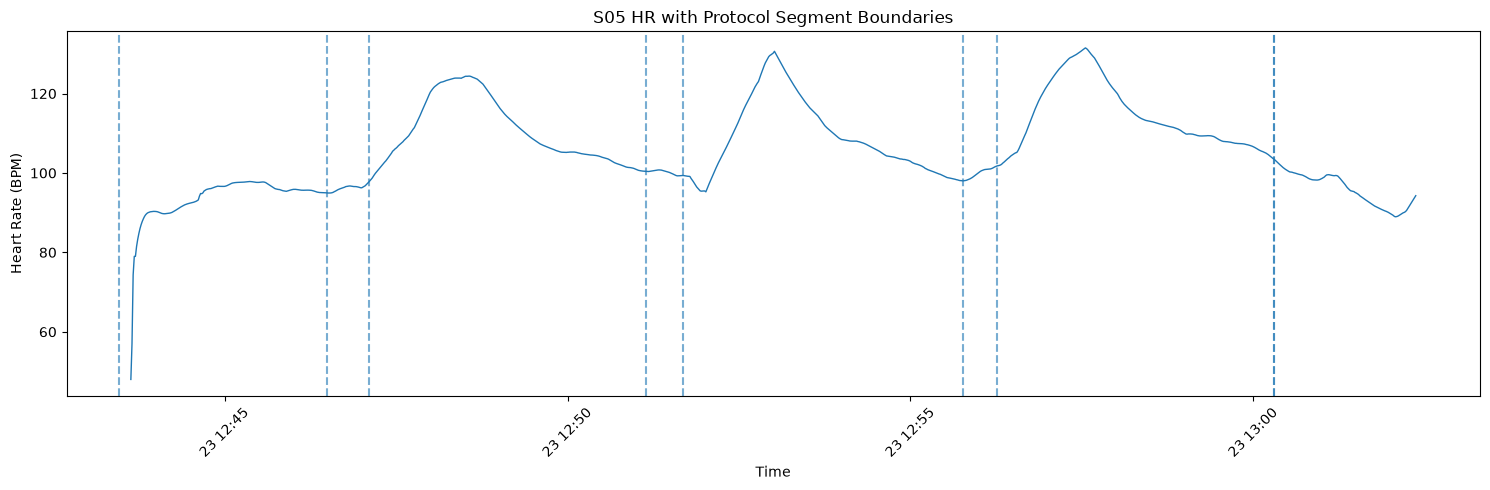

        label               start                        end  duration_sec
0    baseline 2013-02-23 12:43:28 2013-02-23 12:46:30.000000     182.00000
1    sprint_1 2013-02-23 12:46:30 2013-02-23 12:47:06.000000      36.00000
2  cooldown_1 2013-02-23 12:47:06 2013-02-23 12:51:09.000000     243.00000
3    sprint_2 2013-02-23 12:51:09 2013-02-23 12:51:41.000000      32.00000
4  cooldown_2 2013-02-23 12:51:41 2013-02-23 12:55:46.000000     245.00000
5    sprint_3 2013-02-23 12:55:46 2013-02-23 12:56:16.000000      30.00000
6  cooldown_3 2013-02-23 12:56:16 2013-02-23 13:00:18.000000     242.00000
7  final_rest 2013-02-23 13:00:18 2013-02-23 13:02:22.156250     124.15625


In [59]:
# Add final rest to our segment table
final_rest = pd.DataFrame([
    (
        "final_rest",
        final_rest_start,
        final_rest_end
    )
], columns=["label", "start", "end"])

final_rest["duration_sec"] = (
    final_rest["end"] - final_rest["start"]
).dt.total_seconds()

segments_df = pd.concat(
    [segments_df, final_rest],
    ignore_index=True
)

print(segments_df)

def get_segment(signal_df, start, end):
    return signal_df[
        (signal_df["timestamp"] >= start) &
        (signal_df["timestamp"] < end)
    ].copy()

hr_segments = {}

for _, row in segments_df.iterrows():
    segment = get_segment(
        hr_clean,
        row["start"],
        row["end"]
    )

    hr_segments[row["label"]] = segment

    print(
        row["label"],
        "→",
        len(segment),
        "samples"
    )

    plt.figure(figsize=(15, 5))

plt.plot(
    hr_clean["timestamp"],
    hr_clean["HR"],
    linewidth=1
)

for _, row in segments_df.iterrows():
    plt.axvline(
        row["start"],
        linestyle="--",
        alpha=0.6
    )

plt.xlabel("Time")
plt.ylabel("Heart Rate (BPM)")
plt.title("S05 HR with Protocol Segment Boundaries")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

segments_df = segments_df.drop_duplicates(
    subset=["label", "start", "end"]
).reset_index(drop=True)

print(segments_df)



In [27]:
segments = [
    ("baseline",   "2013-02-23 12:43:28", "2013-02-23 12:46:30"),
    ("sprint_1",   "2013-02-23 12:46:30", "2013-02-23 12:47:06"),
    ("cooldown_1", "2013-02-23 12:47:06", "2013-02-23 12:51:09"),
    ("sprint_2",   "2013-02-23 12:51:09", "2013-02-23 12:51:41"),
    ("cooldown_2", "2013-02-23 12:51:41", "2013-02-23 12:55:46"),
    ("sprint_3",   "2013-02-23 12:55:46", "2013-02-23 12:56:16"),
    ("cooldown_3", "2013-02-23 12:56:16", "2013-02-23 13:00:18"),
]

segments_df = pd.DataFrame(
    segments,
    columns=["label", "start", "end"]
)

segments_df["start"] = pd.to_datetime(segments_df["start"])
segments_df["end"] = pd.to_datetime(segments_df["end"])

segments_df["duration_sec"] = (
    segments_df["end"] - segments_df["start"]
).dt.total_seconds()

print(segments_df)

final_rest_start = pd.Timestamp("2013-02-23 13:00:18")
final_rest_end = acc_clean["timestamp"].iloc[-1]

print("Final rest:")
print(final_rest_start)
print(final_rest_end)
print(
    "Duration:",
    (final_rest_end - final_rest_start).total_seconds(),
    "seconds"
)

        label               start                 end  duration_sec
0    baseline 2013-02-23 12:43:28 2013-02-23 12:46:30         182.0
1    sprint_1 2013-02-23 12:46:30 2013-02-23 12:47:06          36.0
2  cooldown_1 2013-02-23 12:47:06 2013-02-23 12:51:09         243.0
3    sprint_2 2013-02-23 12:51:09 2013-02-23 12:51:41          32.0
4  cooldown_2 2013-02-23 12:51:41 2013-02-23 12:55:46         245.0
5    sprint_3 2013-02-23 12:55:46 2013-02-23 12:56:16          30.0
6  cooldown_3 2013-02-23 12:56:16 2013-02-23 13:00:18         242.0
Final rest:
2013-02-23 13:00:18
2013-02-23 13:02:22.156250
Duration: 124.15625 seconds


In [25]:
readme_path = DATA_PATH + "/README.txt"

with open(readme_path, "r", encoding="utf-8") as f:
    readme = f.read()

print(readme)

# FILES
- 'Stress_Level_v1.csv' and 'Stress_Level_v2.csv' contain self-reported stress levels during the stress protocol for each stage of the study,  respectively.
- 'subject-info.csv' contains demographic data such as age, weight, and height for all participants.
- 'data_constraints.txt' contains detailed information of issues such as incorrect wristband placements, incomplete protocols, and connection problems. 
- 'Wearable_Dataset.ipynb'  is a Jupyter Notebook that provides visualizations of all recorded signals and includes sample code for managing the data.
- The main folder 'Wearable_Dataset' contains three folders for each type of activity: 'STRESS', 'AEROBIC' and 'ANAEROBIC'.
- Each of these folders includes participant subfolders named as 'S01','S02','f01',etc.
- Each of the folders corresponding to each participant contains Empatica E4 files: 'ACC.csv', 'BVP.csv', 'EDA.csv', 'HR.csv', 'IBI.csv', 'tags.csv' and 'TEMP.csv'.

# RELEVANT INFO
- Before downloading, we recommend r

In [24]:
tags_path = (
    DATA_PATH +
    "/Wearable_Dataset/ANAEROBIC/S05/tags.csv"
)

with open(tags_path, "r") as f:
    for i in range(15):
        print(i, f.readline().strip())

0 2013-02-23 12:46:30
1 2013-02-23 12:47:06
2 2013-02-23 12:51:09
3 2013-02-23 12:51:41
4 2013-02-23 12:55:46
5 2013-02-23 12:56:16
6 2013-02-23 13:00:18
7 
8 
9 
10 
11 
12 
13 
14 


In [23]:
acc_clean = load_sensor_csv(
    DATA_PATH + "/Wearable_Dataset/ANAEROBIC/S05/ACC.csv",
    "ACC"
)

acc_clean["ACC_MAG"] = np.sqrt(
    acc_clean["ACC_X"]**2 +
    acc_clean["ACC_Y"]**2 +
    acc_clean["ACC_Z"]**2
)

print(acc_clean.head())
print("Shape:", acc_clean.shape)

                   timestamp  ACC_X  ACC_Y  ACC_Z    ACC_MAG
0 2013-02-23 12:43:28.000000   41.0   32.0   38.0  64.412732
1 2013-02-23 12:43:28.031250   43.0   30.0   37.0  64.171645
2 2013-02-23 12:43:28.062500   42.0   30.0   39.0  64.691576
3 2013-02-23 12:43:28.093750   45.0   33.0   34.0  65.345237
4 2013-02-23 12:43:28.125000   41.0   32.0   36.0  63.253458
Shape: (36294, 5)


In [18]:
constraints_path = DATA_PATH + "/data_constraints.txt"

with open(constraints_path, "r", encoding="cp1252") as f:
    constraints = f.read()

print(constraints)

STRESS
•	S02: Files downloaded from E4 Connect have duplicated signals. Duplicated raw values start in: ACC.csv: row 49,545; BVP.csv: row 99,091; EDA.csv and TEMP.csv: row 6,195. As IBI and HR files are obtained from the BVP signal through Empatica's algorithm, it is not evident where the duplicated data start.
•	f07: The protection dock was never removed from the wristband, covering the PPG and TEMPERATURE sensors. Thus, only the ELECTRODERMAL ACTIVITY AND ACCELEROMETER DATA measurements are valid.
•	f14: Bluetooth connection was lost during registration. The baseline is in file f14_a, and the rest of the protocol is in file f14_b.

AEROBIC
•	S03: Ended the protocol early, only reaching 90 rpm.
•	S07: Ended the protocol early, only reaching 95 rpm.
•	S11: Bluetooth connection was lost during registration. File S11_a includes data up to 105 rpm, and S11_b includes the last 110 rpm block.
•	S12: Did not perform the aerobic protocol, so there are no data.

ANAEROBIC
•	S01: The IBI file d

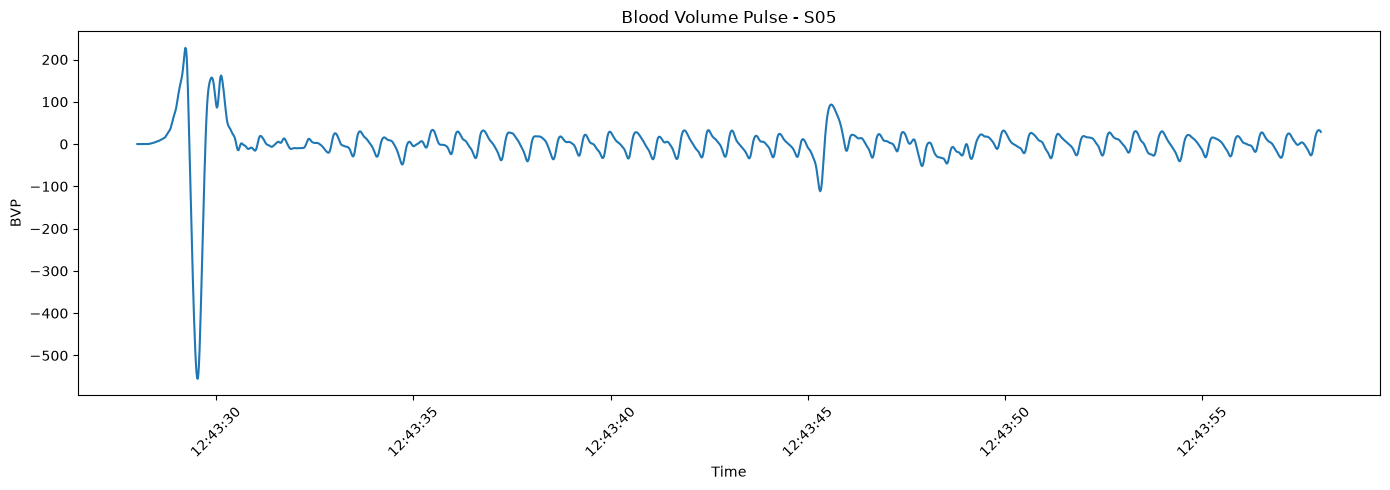

In [16]:
bvp_30 = bvp_clean[
    bvp_clean["timestamp"] <=
    bvp_clean["timestamp"].iloc[0] +
    pd.Timedelta(seconds=30)
]

plt.figure(figsize=(14, 5))

plt.plot(
    bvp_30["timestamp"],
    bvp_30["BVP"]
)

plt.xlabel("Time")
plt.ylabel("BVP")
plt.title("Blood Volume Pulse - S05")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
bvp_path = (
    DATA_PATH +
    "/Wearable_Dataset/ANAEROBIC/S05/BVP.csv"
)

bvp_clean = load_sensor_csv(bvp_path, "BVP")

print(bvp_clean.head())
print()
print("Shape:", bvp_clean.shape)
print()
print(bvp_clean["BVP"].describe())

                   timestamp  BVP
0 2013-02-23 12:43:28.000000 -0.0
1 2013-02-23 12:43:28.015625 -0.0
2 2013-02-23 12:43:28.031250 -0.0
3 2013-02-23 12:43:28.046875 -0.0
4 2013-02-23 12:43:28.062500 -0.0

Shape: (72589, 2)

count    72589.000000
mean         0.004841
std         49.010805
min       -643.810000
25%        -21.680000
50%          0.560000
75%         22.370000
max        436.190000
Name: BVP, dtype: float64


In [14]:
print("HR")
print(hr_clean["HR"].describe())

print("\nEDA")
print(eda_clean["EDA"].describe())

print("\nACC")
print(acc_clean[["ACC_X", "ACC_Y", "ACC_Z", "ACC_MAG"]].describe())

HR
count    1125.000000
mean      105.716764
std        10.845151
min        48.000000
25%        97.770000
50%       104.100000
75%       112.080000
max       131.500000
Name: HR, dtype: float64

EDA
count    4536.000000
mean       41.501456
std        18.581407
min         0.000000
25%        36.254459
50%        48.000366
75%        56.899231
max        63.785847
Name: EDA, dtype: float64

ACC
              ACC_X         ACC_Y         ACC_Z       ACC_MAG
count  36295.000000  36295.000000  36295.000000  36295.000000
mean      30.088139     36.444249     37.892079     64.276497
std       17.476375      9.351371      9.594854      4.768779
min     -128.000000    -85.000000    -54.000000     16.309506
25%       25.000000     33.000000     35.000000     63.031738
50%       34.000000     36.000000     40.000000     63.835727
75%       40.000000     41.000000     43.000000     64.876806
max      127.000000    127.000000    127.000000    185.415749


In [13]:
print("Temperature statistics:")
print(temp_clean["TEMP"].describe())
print("\nUnique temperature values:")
print(temp_clean["TEMP"].value_counts().head(20))
print("\nMinimum:", temp_clean["TEMP"].min())
print("Maximum:", temp_clean["TEMP"].max())
print(
    temp_clean[
        (temp_clean["TEMP"] > 100) |
        (temp_clean["TEMP"] < 0)
    ].head(20)
)

Temperature statistics:
count    4536.000000
mean      142.847337
std        84.460120
min        34.750000
25%        35.370000
50%       208.750000
75%       209.050000
max       220.870000
Name: TEMP, dtype: float64

Unique temperature values:
TEMP
209.05    660
209.07    304
208.69    208
209.41    172
209.43    164
209.45    156
208.75    152
208.71    144
35.47     124
208.73    116
208.91    112
209.13    112
209.03    112
34.84      92
34.93      88
35.49      88
34.95      84
35.45      76
35.50      72
34.89      60
Name: count, dtype: int64

Minimum: 34.75
Maximum: 220.87
                 timestamp    TEMP
0  2013-02-23 12:43:28.000  208.95
1  2013-02-23 12:43:28.250  208.95
2  2013-02-23 12:43:28.500  208.95
3  2013-02-23 12:43:28.750  208.95
4  2013-02-23 12:43:29.000  208.95
5  2013-02-23 12:43:29.250  208.95
6  2013-02-23 12:43:29.500  208.95
7  2013-02-23 12:43:29.750  208.95
8  2013-02-23 12:43:30.000  208.97
9  2013-02-23 12:43:30.250  208.97
10 2013-02-23 12:43:30.50

                   timestamp  ACC_X  ACC_Y  ACC_Z    ACC_MAG
0 2013-02-23 12:43:28.000000   32.0   32.0   32.0  55.425626
1 2013-02-23 12:43:28.031250   41.0   32.0   38.0  64.412732
2 2013-02-23 12:43:28.062500   43.0   30.0   37.0  64.171645
3 2013-02-23 12:43:28.093750   42.0   30.0   39.0  64.691576
4 2013-02-23 12:43:28.125000   45.0   33.0   34.0  65.345237


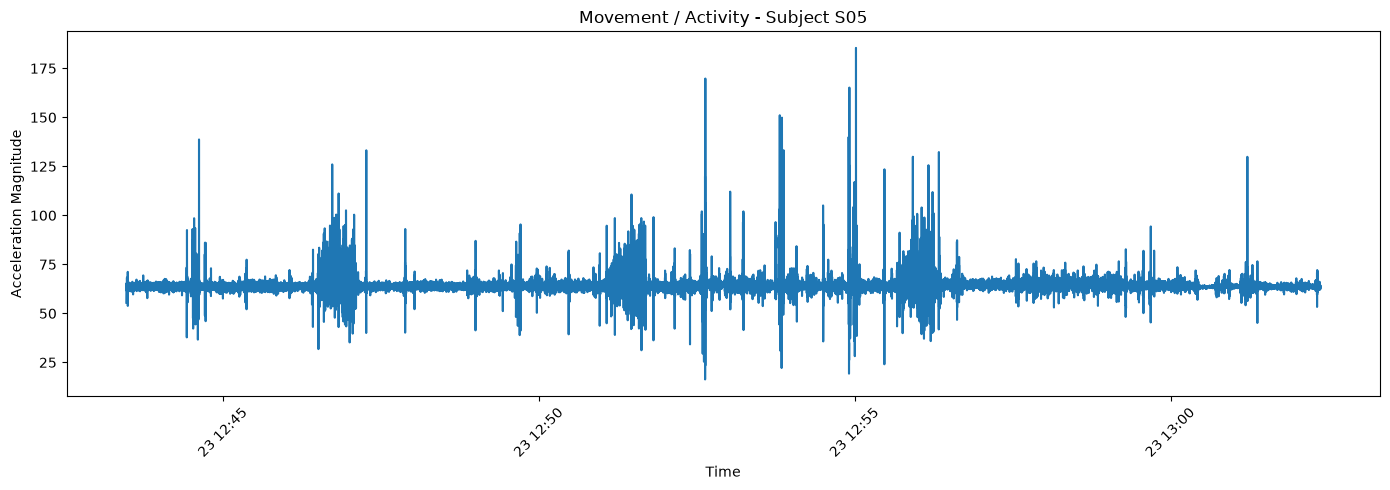

In [12]:
acc_clean["ACC_MAG"] = np.sqrt(
    acc_clean["ACC_X"]**2 +
    acc_clean["ACC_Y"]**2 +
    acc_clean["ACC_Z"]**2
)

print(acc_clean.head())

plt.figure(figsize=(14, 5))

plt.plot(
    acc_clean["timestamp"],
    acc_clean["ACC_MAG"]
)

plt.xlabel("Time")
plt.ylabel("Acceleration Magnitude")
plt.title("Movement / Activity - Subject S05")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

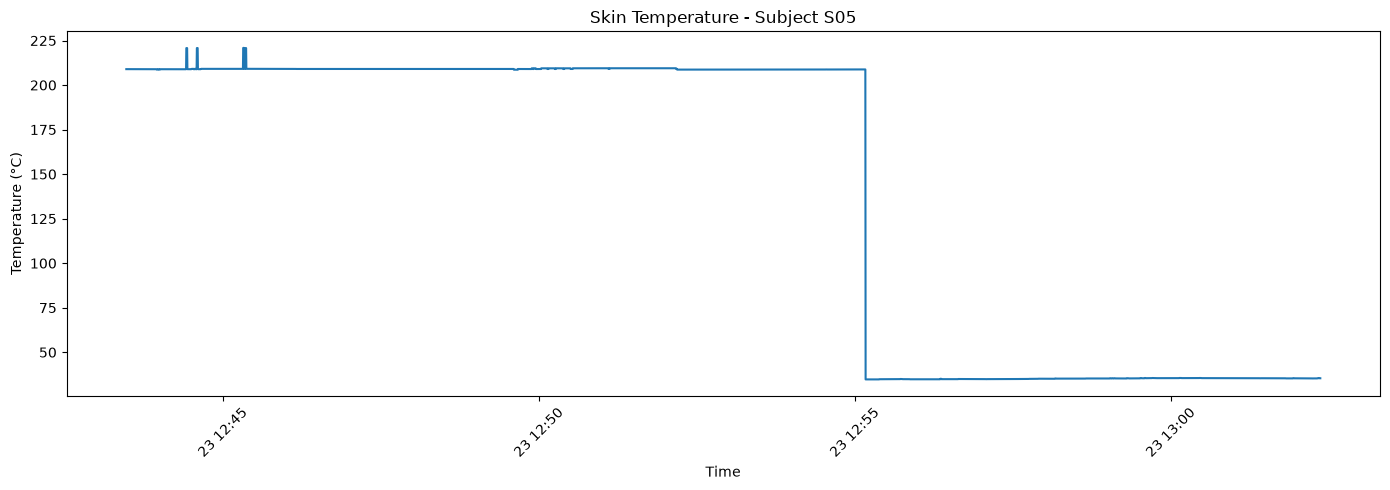

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))

plt.plot(
    temp_clean["timestamp"],
    temp_clean["TEMP"]
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Skin Temperature - Subject S05")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



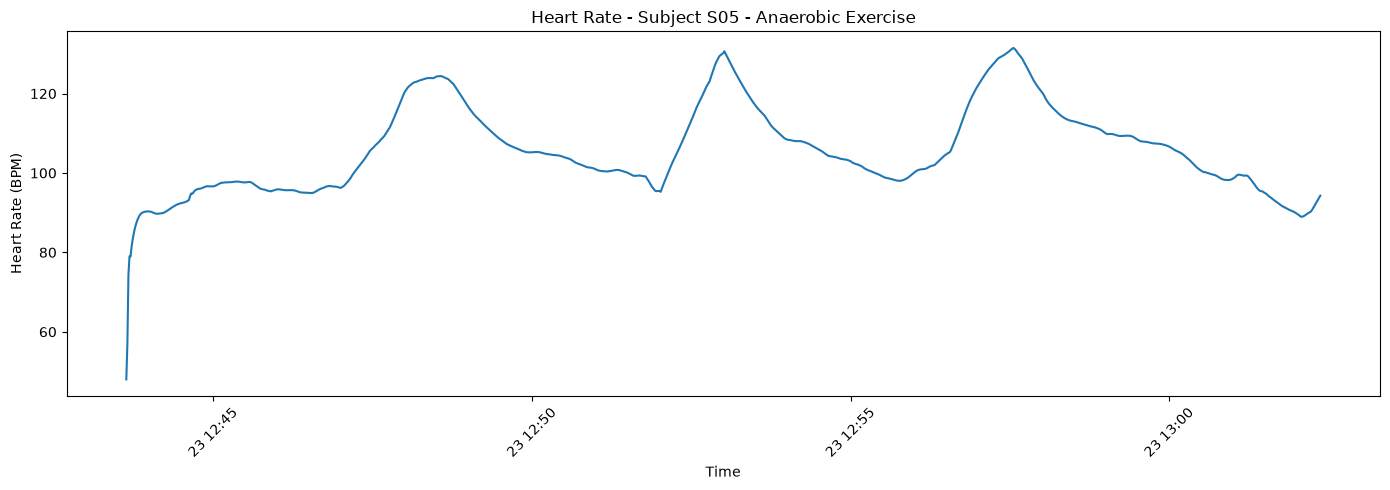

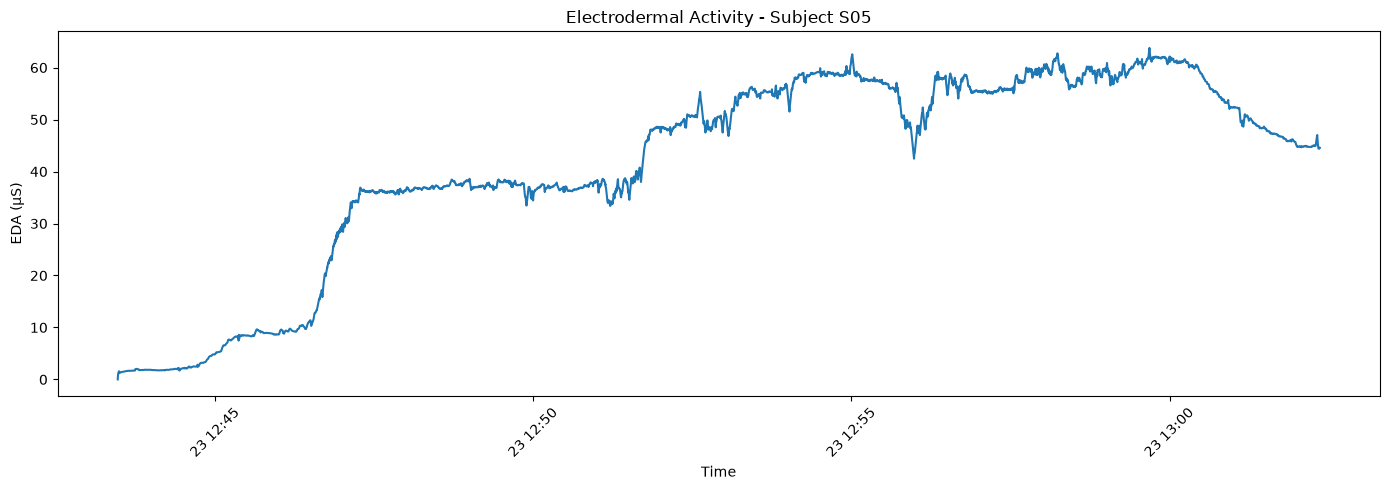

In [ ]:


plt.figure(figsize=(14, 5))

plt.plot(
    hr_clean["timestamp"],
    hr_clean["HR"]
)

plt.xlabel("Time")
plt.ylabel("Heart Rate (BPM)")
plt.title("Heart Rate - Subject S05 - Anaerobic Exercise")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))

plt.plot(
    eda_clean["timestamp"],
    eda_clean["EDA"]
)

plt.xlabel("Time")
plt.ylabel("EDA (µS)")
plt.title("Electrodermal Activity - Subject S05")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
acc_path = (
    DATA_PATH +
    "/Wearable_Dataset/ANAEROBIC/S05/ACC.csv"
)

acc_clean = load_sensor_csv(acc_path, "ACC")

print(acc_clean.head())
print()
print("Shape:", acc_clean.shape)

                   timestamp  ACC_X  ACC_Y  ACC_Z
0 2013-02-23 12:43:28.000000   32.0   32.0   32.0
1 2013-02-23 12:43:28.031250   41.0   32.0   38.0
2 2013-02-23 12:43:28.062500   43.0   30.0   37.0
3 2013-02-23 12:43:28.093750   42.0   30.0   39.0
4 2013-02-23 12:43:28.125000   45.0   33.0   34.0

Shape: (36295, 4)


In [5]:
temp_path = (
    DATA_PATH +
    "/Wearable_Dataset/ANAEROBIC/S05/TEMP.csv"
)

temp_clean = load_sensor_csv(temp_path, "TEMP")

print(temp_clean.head())
print()
print("Shape:", temp_clean.shape)


                timestamp    TEMP
0 2013-02-23 12:43:28.000  208.95
1 2013-02-23 12:43:28.250  208.95
2 2013-02-23 12:43:28.500  208.95
3 2013-02-23 12:43:28.750  208.95
4 2013-02-23 12:43:29.000  208.95

Shape: (4536, 2)


In [4]:
eda_path = (
    DATA_PATH +
    "/Wearable_Dataset/ANAEROBIC/S05/EDA.csv"
)

eda_clean = load_sensor_csv(eda_path, "EDA")

print(eda_clean.head())
print()
print("Shape:", eda_clean.shape)

                timestamp       EDA
0 2013-02-23 12:43:28.000  0.000000
1 2013-02-23 12:43:28.250  0.836457
2 2013-02-23 12:43:28.500  1.183860
3 2013-02-23 12:43:28.750  1.392723
4 2013-02-23 12:43:29.000  1.446523

Shape: (4536, 2)


In [3]:
DATA_PATH = "../data/raw/wearable"
hr_path = (
    DATA_PATH +
    "/Wearable_Dataset/ANAEROBIC/S05/HR.csv"
)

hr_clean = load_sensor_csv(hr_path, "HR")

print(hr_clean.head(10))
print()
print("Shape:", hr_clean.shape)
print()
print(hr_clean.dtypes)

            timestamp     HR
0 2013-02-23 12:43:38  48.00
1 2013-02-23 12:43:39  57.00
2 2013-02-23 12:43:40  74.33
3 2013-02-23 12:43:41  79.00
4 2013-02-23 12:43:42  79.00
5 2013-02-23 12:43:43  81.50
6 2013-02-23 12:43:44  83.29
7 2013-02-23 12:43:45  84.75
8 2013-02-23 12:43:46  86.00
9 2013-02-23 12:43:47  87.00

Shape: (1125, 2)

timestamp    datetime64[us]
HR                  float64
dtype: object


In [21]:
import csv
import pandas as pd
import numpy as np


def load_sensor_csv(file_path, sensor_type):
    """
    Load a wearable sensor CSV and convert it into a clean DataFrame.

    Parameters
    ----------
    file_path : str
        Path to the CSV file.

    sensor_type : str
        One of:
        HR, EDA, TEMP, BVP, IBI, ACC

    Returns
    -------
    pandas.DataFrame
    """

    with open(file_path, "r") as f:
        rows = list(csv.reader(f))

    # First row contains the starting timestamp
    start_time = pd.to_datetime(rows[0][0])

    # --------------------------------------------------
    # ACC has three columns: X, Y, Z
    # --------------------------------------------------
    if sensor_type == "ACC":
        values = np.array(
            [[float(x) for x in row[:3]] for row in rows[2:]],
            dtype=float
        )

        timestamps = pd.date_range(
            start=start_time,
            periods=len(values),
            freq=pd.Timedelta(seconds=1/32)
        )

        df = pd.DataFrame(
            values,
            columns=["ACC_X", "ACC_Y", "ACC_Z"]
        )

        df.insert(0, "timestamp", timestamps)

        return df

    # --------------------------------------------------
    # Other sensors have one value per row
    # --------------------------------------------------

    values = np.array(
        [float(row[0]) for row in rows[2:]],
        dtype=float
    )

    # Sampling frequencies from the dataset
    sampling_rates = {
        "HR": 1,
        "EDA": 4,
        "TEMP": 4,
        "BVP": 64,
        "IBI": None
    }

    rate = sampling_rates[sensor_type]

    if rate is not None:

        timestamps = pd.date_range(
            start=start_time,
            periods=len(values),
            freq=pd.Timedelta(seconds=1/rate)
        )

        df = pd.DataFrame({
            "timestamp": timestamps,
            sensor_type: values
        })

    else:
        # IBI has no fixed sampling frequency
        df = pd.DataFrame({
            "IBI": values
        })

    return df